<a href="https://colab.research.google.com/github/techeiFatima/HandsFree/blob/main/Copy_of_6_7960_Fall_2026_hw2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 2: Architecture and inductive bias

**NOTE:** This notebook covers Questions 9–12 of Homework 2. Include your code, outputs, plots and answers in the PDF submission.

**Reminder:** you should not use AI assistants for this homework, including Colab's AI autocomplete. Please turn it off.

We will use the CIFAR-100 in this question, which has **100** classes, and use CNN models to investigate some interesting aspects of training deep models. Moreover, we will use standard PyTorch `nn.Module`s and `optim.Optimizer`s.

<h2>CIFAR-100</h2>

CIFAR-100  is a image classification dataset.
+ Each data sample is an RGB $32\times32$ real image. A raw loaded image $\in \mathbb{R}^{3 \times 32 \times 32}$.
+ Each image is associated with a label $\in \{0,1,2,\dots, 99\}$.


Our goal is to train a neural network classifier that takes such $3\times32\times32$ images and predict a label $\in \{0, 1, 2, \dots, 99\}$.

In [ ]:
# install dependencies

!pip install torch torchvision

This notebook runs on a CPU-only Colab runtime in a reasonable amount of time. If a GPU is available, it will be used automatically and training will be faster.

In [ ]:
%matplotlib inline

from typing import *

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import dataclasses
from tqdm.auto import tqdm

import torchvision
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.utils import make_grid

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cpu


## Dataset
Let's reuse the homework 1 augmented dataset code, but now modified to work on **CIFAR-100**. Code is hidden in the cell below, but make sure to still run it.

Training set size: 50000
Validation set size: 10000
CIFAR-100 classes: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine', 'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose', 'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider', 'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 'television', 'tiger', 'tractor', '

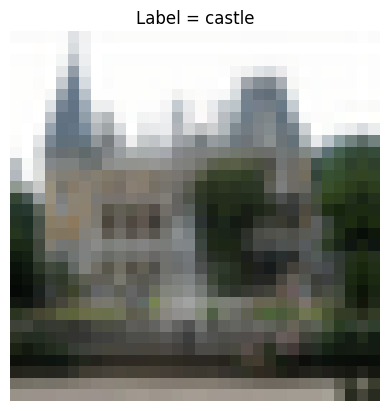

In [ ]:
#@title
%matplotlib inline

import torchvision
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


def get_datasets(train_transforms=(), val_transforms=()):
    r"""
    Returns the CIFAR-100 training and validation datasets with corresponding
    transforms.

    `*_transforms` represent optional transformations, e.g., conversion to
    PyTorch tensors, preprocessing, etc.
    """
    train_set = torchvision.datasets.CIFAR100(
        './data', train=True, download=True,
        transform=torchvision.transforms.Compose(train_transforms))
    val_set = torchvision.datasets.CIFAR100(
        './data', train=False, download=True,
        transform=torchvision.transforms.Compose(val_transforms))
    return train_set, val_set


cifar100_mean = torch.as_tensor([0.5071, 0.4865, 0.4409])
cifar100_std = torch.as_tensor([0.2673, 0.2564, 0.2762])

train_transforms = [
    torchvision.transforms.RandomCrop(32, padding=3, padding_mode='reflect'),
    torchvision.transforms.RandomHorizontalFlip(p=0.5),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(mean=cifar100_mean, std=cifar100_std),
]

val_transforms = [
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(mean=cifar100_mean, std=cifar100_std),
]

train_set, val_set = get_datasets(train_transforms, val_transforms)

print(f"Training set size: {len(train_set)}")
print(f"Validation set size: {len(val_set)}")

class_names = train_set.classes
print(f'CIFAR-100 classes: {class_names}')

def visualize_tensor_data(data: torch.Tensor, label: int):
    # Data is a tensor of shape [C, W, H]  (C is the channel dimension, 3 for RGB)
    # Put channel at last
    data = data.permute(1, 2, 0)
    # Un-normalize
    data = data * cifar100_std + cifar100_mean

    plt.imshow(data)
    plt.axis('off')
    plt.title(f'Label = {class_names[label]}')

data, label = train_set[13]
visualize_tensor_data(data, label)

## Network Definition (Question 9)

 Implement the following function that creates the specified CNN networks. Read through the docstring and make sure that your implementation behaves as required. Afterwards, print the outputs of
+ `make_cnn(100, 'tanh', num_conv_layers=5, num_fc_layers=4)`
+ `make_cnn(3, 'none', num_conv_layers=3, num_fc_layers=2)`

Add both your implementation and outputs to the writeup.

---

Links you may find useful:
+ `none` activation: https://pytorch.org/docs/stable/generated/torch.nn.Identity.html?highlight=identity#torch.nn.Identity
+ Chaining layers: https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html?highlight=sequential#torch.nn.Sequential
+ Reshaping image-like tensors to vectors: https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html?highlight=flatten#torch.nn.Flatten

(You are not required to use these classes)


In [ ]:
def make_mlp(num_inputs: int, num_outputs: int, activation: str, hidden_sizes: int = [128]) -> nn.Module:

    if activation == 'relu':
        act_cls = nn.ReLU
    elif activation == 'tanh':
        act_cls = nn.Tanh
    elif activation == 'none':
        act_cls = nn.Identity
    else:
        raise ValueError(f'Unexpected activation={repr(activation)}')

    net = [nn.Flatten(),
           nn.Linear(num_inputs, hidden_sizes[0]),
           act_cls()]

    for i in range(1, len(hidden_sizes)):
      net.extend([nn.Linear(hidden_sizes[i-1], hidden_sizes[i]),
                  act_cls()])

    net.extend([nn.Linear(hidden_sizes[-1], num_outputs)])

    return nn.Sequential(*net)

In [ ]:
def make_cnn(num_outputs: int, activation: str, num_conv_layers: int = 4, num_fc_layers: int = 2) -> nn.Module:
    r'''
    Returns a PyTorch module representing a CNN network that takes in image-like input with shape [3, 32, 32].

    Args:
        num_outputs (int): size of the final output layer. E.g., if the network is a classifier, this is usually #classes.
        activation (str): activation functions between conv/linear layers. Supported choices are ['relu', 'tanh', 'none'] (always strings).
            For 'none', no activation function is applied, and the previous conv/linear output is directly fed into the next conv/linear.
        num_conv_layers (int): number of conv layers in CNN. This should be >= 3 and <= 5.
            First conv layer should always use 5x5 kernels, mapping 3-channel data to 12-channel data, with **reflect** padding=2 and no striding.
            Subsequent conv layers should always use 3x3 kernels, mapping to 64-channel data, with zeros (default) padding=1 and strides=2.
        num_fc_layers (int): number of fc/linear layers after the convolutional part. This should be >= 2.
            For all but the last fc layer, it should output 128-dimensional vectors.

    Returns:
        (nn.Module) The CNN network of desired tructure.

    If an unexpected input is given, this will raise a ValueError. (You can assume that arguments are of correct types.)
    '''
    if activation == "relu":
        act_cls = nn.ReLU
    elif activation == "tanh":
        act_cls = nn.Tanh
    elif activation == "none":
        act_cls = nn.Identity
    else:
        raise ValueError(f'Unexpected activation={repr(activation)}')

    if not (3 <= num_conv_layers <= 5):
        raise ValueError(f'num_conv_layers must be between 3 and 5, got {num_conv_layers}')
    if num_fc_layers < 2:
        raise ValueError(f'num_fc_layers must be >= 2, got {num_fc_layers}')

    layers = []
    # First conv layer: 5x5 kernels, 3 -> 12 channels, padding_mode='reflect', padding=2
    layers.append(nn.Conv2d(3, 12, kernel_size=5, stride=1, padding=2, padding_mode='reflect'))
    layers.append(act_cls())

    # Subsequent conv layers: 3x3 kernels, mapping to 64 channels, stride=2, padding=1
    for _ in range(1, num_conv_layers):
        layers.append(nn.Conv2d(layers[-2].out_channels, 64, kernel_size=3, stride=2, padding=1))
        layers.append(act_cls())

    # Flatten layer
    layers.append(nn.Flatten())

    # Determine the flattened feature dimension dynamically
    with torch.no_grad():
        dummy_input = torch.zeros(1, 3, 32, 32)
        dummy_output = nn.Sequential(*layers)(dummy_input)
        flattened_dim = dummy_output.shape[1]

    # FC Layers
    in_features = flattened_dim
    for _ in range(num_fc_layers - 1):
        layers.append(nn.Linear(in_features, 128))
        layers.append(act_cls())
        in_features = 128

    # Final output layer
    layers.append(nn.Linear(in_features, num_outputs))

    return nn.Sequential(*layers)

In [ ]:
print('num_outputs=100, tanh, hidden_sizes=[128, 120]')
print(make_mlp(10, 100, 'tanh', hidden_sizes=[128, 120]))
print()
print('num_outputs=100, tanh, num_conv_layers=5, num_fc_layers=4:')
print(make_cnn(100, 'tanh', num_conv_layers=5, num_fc_layers=4))
print()
print('num_outputs=3, no activation, num_conv_layers=3, num_fc_layers=2:')
print(make_cnn(3, 'none', num_conv_layers=3, num_fc_layers=2))

num_outputs=100, tanh, hidden_sizes=[128, 120]
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=10, out_features=128, bias=True)
  (2): Tanh()
  (3): Linear(in_features=128, out_features=120, bias=True)
  (4): Tanh()
  (5): Linear(in_features=120, out_features=100, bias=True)
)

num_outputs=100, tanh, num_conv_layers=5, num_fc_layers=4:
Sequential(
  (0): Conv2d(3, 12, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), padding_mode=reflect)
  (1): Tanh()
  (2): Conv2d(12, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (3): Tanh()
  (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (5): Tanh()
  (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (7): Tanh()
  (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (9): Tanh()
  (10): Flatten(start_dim=1, end_dim=-1)
  (11): Linear(in_features=256, out_features=128, bias=True)
  (12): Tanh()
  (13): Linear(in_features=128, out_features=12

## Training loop (Question 10)

 Implement the following training and evaluate functions according to docstring. Complete the `FIXME`s in `train_epoch`, `evaluate`, and `train`. Attach your code to PDF.

---

Links you may find useful:
+ Classification loss: https://pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html?highlight=cross_entropy#torch.nn.functional.cross_entropy
+ Learning rate adjustment: https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate

(You are not required to use these classes)


In [ ]:
def train_epoch(epoch: int, model: nn.Module, train_loader: torch.utils.data.DataLoader, optim: torch.optim.Optimizer):
    r"""
    Trains `model` on `train_loader` for cross entropy loss for one epoch.

    Args:
        epoch (int): the current epoch number (i.e., number of epochs done before this one).
        model (nn.Module): our network (created using `make_cnn`).
        train_loader (DataLoader): a DataLoader that yields (batched_images, batched_target_class_indices) when iterated.
        optim (Optimizer): optimizer object that is created with `model` parameters and should be used for updating `model` in this function.

    Returns:
        (List[float]) the losses computed at each iteration as a list of *Python* numbers.

    NOTE:
      + Remember to clear previously computed gradient at beginning of each iteration.
      + Convert loss values to python floats (e.g., via `.item()`) before adding to `loss_values`.
    """
    loss_values = []

    for data, target in tqdm(train_loader, desc=f'Training @ epoch {epoch}'):
      optim.zero_grad()
      output = model(data)
      loss = F.cross_entropy(output, target)
      loss.backward()
      optim.step()
      loss_values.append(loss.item())
    return loss_values

In [ ]:
@dataclasses.dataclass
class EvaluateResult:
    r"""
    A collection containing everything we need to know about the evaluate results.

    See `evaluate` docstring for meanings of the members of this class
    """
    acc: float  # overall accuracy
    correct_predictions: torch.Tensor  # size |dataset|
    confidence: torch.Tensor  # size |dataset|


@torch.no_grad()
def evaluate(model: nn.Module, loader: torch.utils.data.DataLoader) -> EvaluateResult:
    r"""
    Evaluate a classifier `model` on dataset contained in `loader`.

    For each input, the predicted label is taken as one with highest probability in the distribution given by `model`.

    In addition to compute overall accuracies, we also output
        (1) a boolean Tensor with size |dataset|, showing whether each sample is correctly classified.
        (2) a float32 Tensor with size |dataset|, showing the `model`'s assigned probability for its prediction, called *confidence*.

    Args:
        model (nn.Module): our network (created using `make_cnn`).
        loader (DataLoader): a DataLoader that yields (batched_images, batched_target_class_indices) when iterated.

    Returns:
        (EvaluateResult) Containing overall accuracy, whether each sample is correctly classified, and confidence.
            The tensors should be on **CPU**.
    """
    model.eval()
    all_correct = []
    all_confidences = []

    for data, target in tqdm(loader, desc='Evaluating', leave=False):
        data, target = data.to(device), target.to(device)
        output = model(data)

        # Convert raw logits to probabilities
        probs = F.softmax(output, dim=1)
        conf, pred = probs.max(dim=1)

        correct = (pred == target)

        all_correct.append(correct.cpu())
        all_confidences.append(conf.cpu())

    correct_predictions = torch.cat(all_correct, dim=0)
    confidence = torch.cat(all_confidences, dim=0)
    acc = float(correct_predictions.sum().item()) / len(correct_predictions)

    return EvaluateResult(acc=acc, correct_predictions=correct_predictions, confidence=confidence)

In [ ]:
@dataclasses.dataclass
class TrainResult:
    r"""
    A collection containing everything we need to know about the training results
    """
    num_epochs: int

    # Training loss (saved at each iteration in `train_epoch`)
    train_losses: List[float]

    # The epochs where we perform evaluation
    eval_epochs: List[int]

    # Training accuracies, computed at each epoch in `eval_epochs`
    train_accs: List[float]

    # Validation accuracies, computed at each epoch in `eval_epochs`
    val_accs: List[float]

    # The last validation evaluation full result
    final_val_eval_result: EvaluateResult = None


def train(model: nn.Module, train_set, val_set, *, num_epochs=20, lr=0.003, train_epoch_fn=train_epoch, **kwargs):
    r"""
    Train `model` on `train_set` for `num_epochs` epochs using **Adam** optimizer and `lr` learning rate
    following a decay schedule by a factor of `0.3` at epoch 5`.

    Args:
        model (nn.Module): our network (created using `make_cnn`).
        train_set (Dataset): CIFAR-100 training dataset.
        val_set (Dataset): CIFAR-100 validation dataset. Evaluated every *5* epochs and at the end of training.
        num_epochs (int): number of total training epochs.
        lr (float): initial learning rate.
        train_epoch_fn (Callable): function that trains the model for a single epoch. This is `train_epoch`
            usually, but we will use different choices in later questions.

    Returns:
        (TrainResult)
    """
    # Data loaders
    train_loader = torch.utils.data.DataLoader(train_set, batch_size=512, shuffle=True)  # Random order for training ("[S]tochastic" in SGD)
    val_loader = torch.utils.data.DataLoader(val_set, batch_size=1024, shuffle=False)

    # Our classifier
    print('Model =', model)

    # Create optimizer and lr scheduler
    optim = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.StepLR(optim, step_size=5, gamma=0.3)

    result: TrainResult = TrainResult(num_epochs, train_losses=[], eval_epochs=[], train_accs=[], val_accs=[])
    last_eval_epoch = -float('inf')

    # Iterate through the entire training dataset `num_epochs` times
    for epoch in range(num_epochs):
        if epoch - last_eval_epoch >= 5:
            result.eval_epochs.append(epoch)
            result.train_accs.append(evaluate(model, train_loader).acc)
            result.val_accs.append(evaluate(model, val_loader).acc)
            print(f"Epoch = {epoch:> 2d}    Train acc = {result.train_accs[-1]:.2%}    Val acc = {result.val_accs[-1]:.2%}")
            last_eval_epoch = epoch
        # Train over the entire `train_set` with given `train_epoch_fn` function (i.e., one epoch)
        result.train_losses.extend(train_epoch_fn(epoch, model, train_loader, optim, **kwargs))
        # Evaluate with our `evaluate` function
        print(f"Epoch = {epoch:> 2d}    Train loss = {result.train_losses[-1]:.4f}")

        # Adjust learning rate if needed
        scheduler.step()

    result.eval_epochs.append(num_epochs)
    result.train_accs.append(evaluate(model, train_loader).acc)
    result.final_val_eval_result = evaluate(model, val_loader)
    result.val_accs.append(result.final_val_eval_result.acc)
    print(f"Epoch = {num_epochs:> 2d}    Train acc = {result.train_accs[-1]:.2%}    Val acc = {result.val_accs[-1]:.2%}")

    return result

We provide the following learning curve plotting function (similar to homework 1).

In [ ]:
def learning_curve(result: TrainResult, *, title: str = 'Learning Curve'):
    r"""
    Plot the training loss, training accuracy, and validation accuracy versus
    epochs taken.
    """
    fig, ax_loss = plt.subplots(figsize=(8, 5))
    ax_loss.set_title(title, fontsize=16)
    ax_loss.set_xlabel('Epoch', fontsize=12)

    l_trloss = ax_loss.plot(
        torch.arange(len(result.train_losses)) / len(result.train_losses) * result.num_epochs,
        result.train_losses,
        label='Train loss',
        color='C0',
    )
    ax_loss.set_ylim(0, 4.8)
    ax_loss.set_ylabel('Train loss', color='C0', fontsize=12)
    ax_loss.tick_params(axis='y', labelcolor='C0')

    ax_acc = ax_loss.twinx()
    l_tracc = ax_acc.plot(result.eval_epochs, result.train_accs, label='Train acc', color='C1', linestyle='--')
    if len(result.val_accs):
        l_valacc = ax_acc.plot(result.eval_epochs, result.val_accs, label='Val acc', color='C1')
    else:
        l_valacc = []
    ax_acc.set_ylim(0, 1)
    ax_acc.set_ylabel('Accuracies', color='C1', fontsize=12)
    ax_acc.tick_params(axis='y', labelcolor='C1')

    lines = l_trloss + l_tracc + l_valacc
    ax_loss.legend(lines, [l.get_label() for l in lines], loc='upper left', fontsize=13)

## Comparing architectures (Question 11)

Train each of the 3 architectures for **20 epochs** (the default of `train`) and plot its learning curve. Then:
+ **(a)** plot the validation accuracy of the 3 architectures in a single plot;
+ **(b)** report the number of trainable parameters of each model.

Model = Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=3072, out_features=128, bias=True)
  (2): Tanh()
  (3): Linear(in_features=128, out_features=128, bias=True)
  (4): Tanh()
  (5): Linear(in_features=128, out_features=128, bias=True)
  (6): Tanh()
  (7): Linear(in_features=128, out_features=100, bias=True)
)


Evaluating:   0%|          | 0/98 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch =  0    Train acc = 0.96%    Val acc = 1.01%


Training @ epoch 0:   0%|          | 0/98 [00:00<?, ?it/s]

...

Training @ epoch 19:   0%|          | 0/98 [00:00<?, ?it/s]

Epoch =  19    Train loss = 3.3702


Evaluating:   0%|          | 0/98 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch =  20    Train acc = 19.85%    Val acc = 19.90%


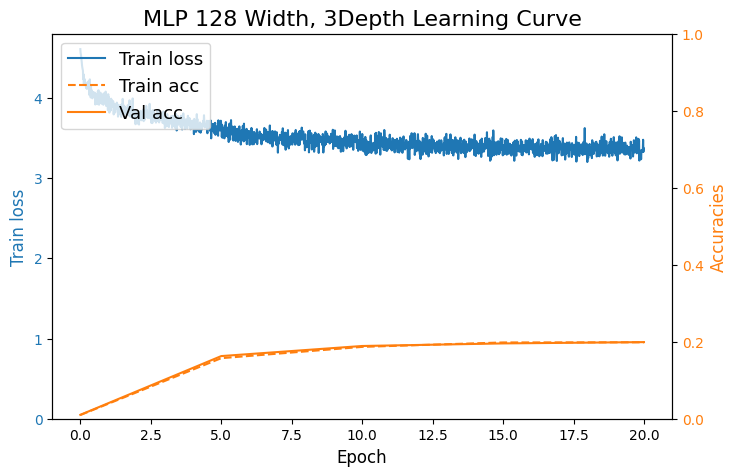

In [ ]:
# Create a MLP 128 width, 3 depth, train it, and plot learning curves.
model1 = make_mlp(3072, 100, 'tanh', hidden_sizes=[128, 128, 128])
model1 = model1.to(device)
result1 = train(model1, train_set, val_set, num_epochs=20)
learning_curve(result1, title='MLP 128 Width, 3Depth Learning Curve')

Model = Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=3072, out_features=128, bias=True)
  (2): Tanh()
  (3): Linear(in_features=128, out_features=128, bias=True)
  (4): Tanh()
  (5): Linear(in_features=128, out_features=128, bias=True)
  (6): Tanh()
  (7): Linear(in_features=128, out_features=128, bias=True)
  (8): Tanh()
  (9): Linear(in_features=128, out_features=128, bias=True)
  (10): Tanh()
  (11): Linear(in_features=128, out_features=128, bias=True)
  (12): Tanh()
  (13): Linear(in_features=128, out_features=128, bias=True)
  (14): Tanh()
  (15): Linear(in_features=128, out_features=100, bias=True)
)


Evaluating:   0%|          | 0/98 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch =  0    Train acc = 1.02%    Val acc = 1.04%


Training @ epoch 0:   0%|          | 0/98 [00:00<?, ?it/s]

...

Training @ epoch 19:   0%|          | 0/98 [00:00<?, ?it/s]

Epoch =  19    Train loss = 3.6635


Evaluating:   0%|          | 0/98 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch =  20    Train acc = 16.89%    Val acc = 16.68%


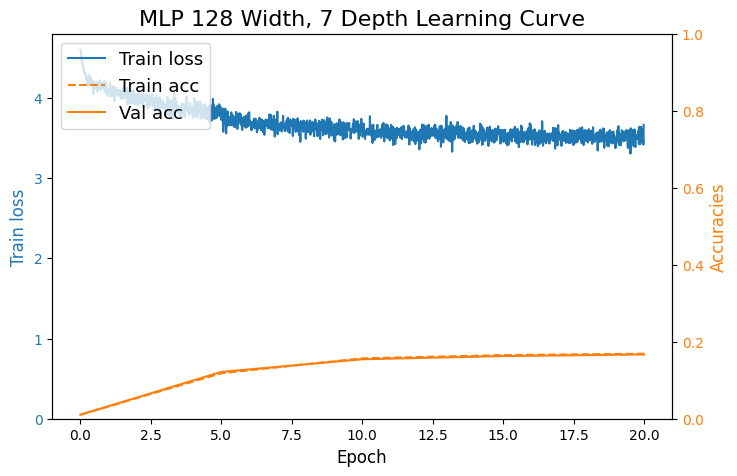

In [ ]:
# Create a MLP 128 width, 7 depth, train it, and plot learning curves.
model2 = make_mlp(3072, 100, 'tanh', hidden_sizes=[128, 128, 128, 128, 128, 128, 128])
model2 = model2.to(device)
result2 = train(model2, train_set, val_set, num_epochs=20)
learning_curve(result2, title='MLP 128 Width, 7 Depth Learning Curve')

Model = Sequential(
  (0): Conv2d(3, 12, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), padding_mode=reflect)
  (1): Tanh()
  (2): Conv2d(12, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (3): Tanh()
  (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (5): Tanh()
  (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (7): Tanh()
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): Linear(in_features=1024, out_features=128, bias=True)
  (10): Tanh()
  (11): Linear(in_features=128, out_features=128, bias=True)
  (12): Tanh()
  (13): Linear(in_features=128, out_features=100, bias=True)
)


Evaluating:   0%|          | 0/98 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch =  0    Train acc = 1.11%    Val acc = 1.06%


Training @ epoch 0:   0%|          | 0/98 [00:00<?, ?it/s]

...

Training @ epoch 19:   0%|          | 0/98 [00:00<?, ?it/s]

Epoch =  19    Train loss = 2.7357


Evaluating:   0%|          | 0/98 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch =  20    Train acc = 31.70%    Val acc = 31.18%


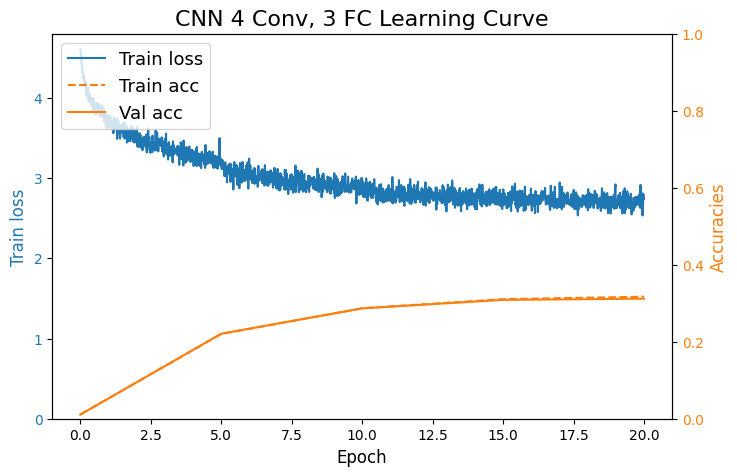

In [ ]:
# Create a CNN 4 convolutional layers, 3 MLP layers, train it, and plot learning curves.
model3 = make_cnn(100, 'tanh', num_conv_layers=4, num_fc_layers=3)
model3 = model3.to(device)
result3 = train(model3, train_set, val_set, num_epochs=20)
learning_curve(result3, title='CNN 4 Conv, 3 FC Learning Curve')

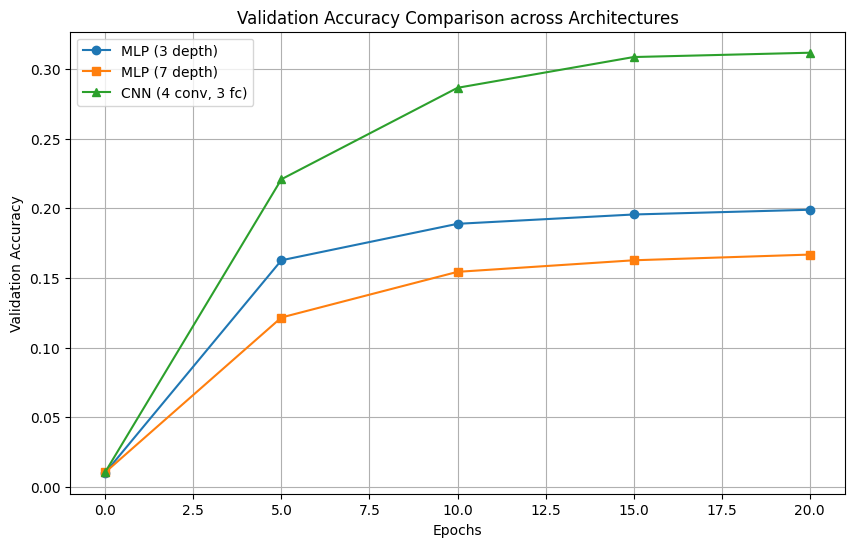

In [ ]:
# (a) Plot the validation accuracy of the 3 architectures in a single plot.
plt.figure(figsize=(10, 6))
plt.plot(result1.eval_epochs, result1.val_accs, label='MLP (3 depth)', marker='o')
plt.plot(result2.eval_epochs, result2.val_accs, label='MLP (7 depth)', marker='s')
plt.plot(result3.eval_epochs, result3.val_accs, label='CNN (4 conv, 3 fc)', marker='^')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy Comparison across Architectures')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# (b) Report the number of trainable parameters of each model.
def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'Trainable parameters of MLP (3 depth): {count_parameters(model1):,}')
print(f'Trainable parameters of MLP (7 depth): {count_parameters(model2):,}')
print(f'Trainable parameters of CNN (4 conv, 3 fc): {count_parameters(model3):,}')

Trainable parameters of MLP (3 depth): 439,268
Trainable parameters of MLP (7 depth): 505,316
Trainable parameters of CNN (4 conv, 3 fc): 242,356


## Scrambled pixels (Question 12)

**Write your prediction for Question 12(a) in your PDF before running the cells below.**

We fix one random permutation of the $32\times32$ pixel locations and apply the *same* permutation to every image (training and validation, all 3 channels). The cell below creates scrambled versions of the datasets, so you can reuse `train` without changes.

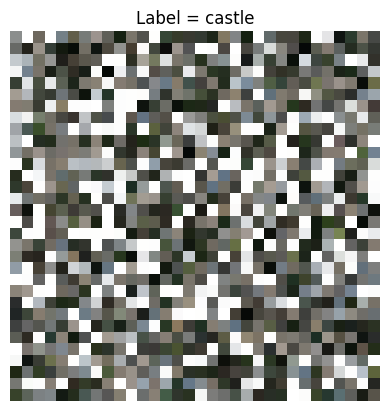

In [ ]:
g = torch.Generator().manual_seed(0)
perm = torch.randperm(32 * 32, generator=g)

def scramble(x):  # x: (B, 3, 32, 32)
    return x.flatten(2)[:, :, perm].reshape(x.shape)

# Apply `scramble` to every image, after the usual transforms
scramble_transform = torchvision.transforms.Lambda(lambda img: scramble(img.unsqueeze(0)).squeeze(0))
scr_train_set, scr_val_set = get_datasets(train_transforms + [scramble_transform],
                                          val_transforms + [scramble_transform])

# Same image as before, now scrambled
data, label = scr_train_set[13]
visualize_tensor_data(data, label)

In [20]:
print("Training MLP on Scrambled Dataset")
model1_scr = make_mlp(3072, 100, 'tanh', hidden_sizes=[128, 128, 128])
model1_scr = model1_scr.to(device)
result1_scr = train(model1_scr, scr_train_set, scr_val_set, num_epochs=20)

print("Training CNN on Scrambled Dataset")
model3_scr = make_cnn(100, 'tanh', num_conv_layers=4, num_fc_layers=3)
model3_scr = model3_scr.to(device)
result3_scr = train(model3_scr, scr_train_set, scr_val_set, num_epochs=20)

Training MLP on Scrambled Dataset
Model = Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=3072, out_features=128, bias=True)
  (2): Tanh()
  (3): Linear(in_features=128, out_features=128, bias=True)
  (4): Tanh()
  (5): Linear(in_features=128, out_features=128, bias=True)
  (6): Tanh()
  (7): Linear(in_features=128, out_features=100, bias=True)
)


Evaluating:   0%|          | 0/98 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch =  0    Train acc = 0.89%    Val acc = 0.84%


Training @ epoch 0:   0%|          | 0/98 [00:00<?, ?it/s]

...

Training @ epoch 19:   0%|          | 0/98 [00:00<?, ?it/s]

Epoch =  19    Train loss = 2.9721


Evaluating:   0%|          | 0/98 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch =  20    Train acc = 25.60%    Val acc = 24.77%


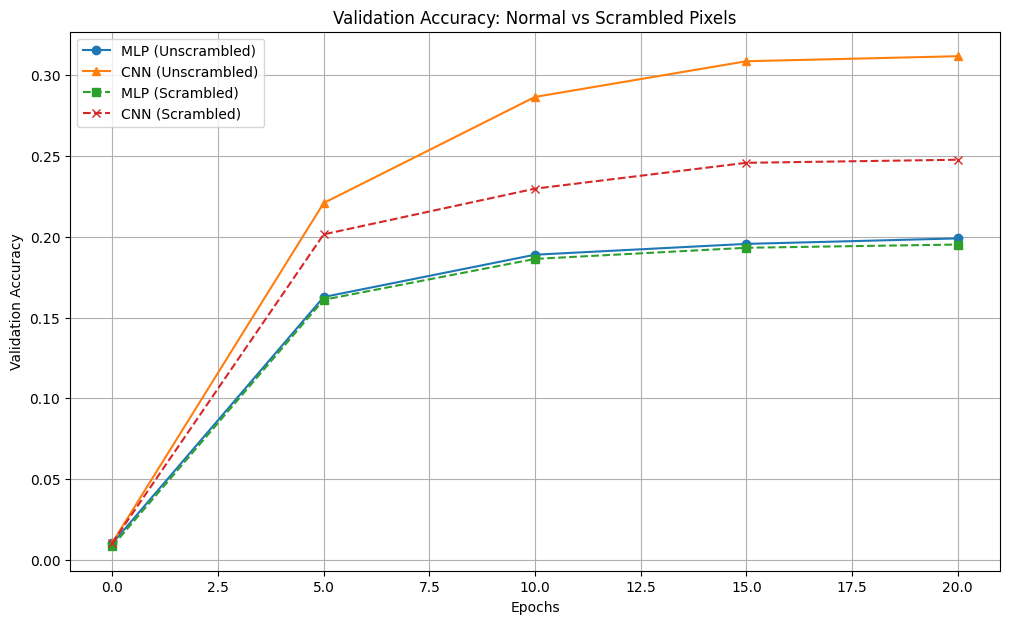

In [21]:
plt.figure(figsize=(12, 7))
plt.plot(result1.eval_epochs, result1.val_accs, label='MLP (Unscrambled)', marker='o', linestyle='-')
plt.plot(result3.eval_epochs, result3.val_accs, label='CNN (Unscrambled)', marker='^', linestyle='-')
plt.plot(result1_scr.eval_epochs, result1_scr.val_accs, label='MLP (Scrambled)', marker='s', linestyle='--')
plt.plot(result3_scr.eval_epochs, result3_scr.val_accs, label='CNN (Scrambled)', marker='x', linestyle='--')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy: Normal vs Scrambled Pixels')
plt.legend()
plt.grid(True)
plt.show()